
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of stocks from the S&P 400.  Construct portfolios from the 400 stocks in the S&P 400 mid cap index and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp400-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,AA,Alcoa,US Stocks:Materials,147.83,294.83,181.09,170.05,31.11,17.67,46.06,22.14,28.38,45.85,52.08,31.11,45.85,0.68
1,AAL,American Airlines Group,US Stocks:Industrials,57.42,18.30,28.08,25.86,1.33,-8.29,49.52,19.06,45.22,44.50,41.88,1.33,44.50,0.03
2,AAON,AAON,US Stocks:Industrials,270.22,122.83,45.01,42.65,33.33,26.44,117.26,23.15,67.07,53.97,47.81,33.33,53.97,0.62
3,ACI,Albertsons,US Stocks:Consumer Staples,-39.77,-21.89,-27.08,-25.80,-5.35,4.61,30.23,18.15,18.25,16.77,27.27,-5.35,16.77,-89.72
4,ACM,AECOM,US Stocks:Industrials,-74.50,-54.80,-35.15,-34.48,-2.99,2.30,44.82,41.40,33.52,28.51,26.24,-2.99,28.51,-85.24
5,ADC,Agree Realty,US Stocks:Real Estate,-24.82,2.41,3.08,2.67,9.22,5.94,11.15,7.44,15.70,17.29,18.09,9.22,17.29,0.53
6,AEIS,Advanced Energy,US Stocks:Technology,-34.16,115.61,161.64,170.31,48.41,25.70,60.64,44.21,46.43,39.71,37.72,48.41,39.71,1.22
7,AFG,American Financial Group,US Stocks:Financials,-6.74,-6.36,12.39,12.63,10.17,10.85,14.71,8.73,17.81,19.29,20.70,10.17,19.29,0.53
8,AGCO,AGCO,US Stocks:Industrials,-53.75,3.05,11.21,13.40,0.72,-0.40,36.32,22.52,33.00,29.90,33.05,0.72,29.90,0.02
9,AHR,American Healthcare REIT,US Stocks:Real Estate,-21.63,2.56,44.21,44.81,44.21,44.21,29.85,17.15,24.29,30.79,30.79,44.21,30.79,1.44


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=1)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered = rank_filtered.head(20)
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
346,TLN,Talen Energy,US Stocks:Utilities,18.19,4.16,58.19,55.56,58.19,58.19,63.29,31.52,42.38,35.54,35.54,58.19,35.54,1.64
354,TTMI,TTM Technologies,US Stocks:Technology,671.37,542.97,479.84,530.59,135.15,63.04,62.71,36.90,70.60,61.69,54.70,135.15,61.69,2.19
92,CTRE,CareTrust REIT,US Stocks:Real Estate,6.44,25.95,48.49,47.29,34.40,17.88,28.62,11.24,17.71,18.95,24.82,34.40,18.95,1.82
64,CDE,Coeur Mining,US Stocks:Materials,-74.24,64.73,129.44,130.33,80.12,14.52,67.79,34.81,76.24,67.50,62.77,80.12,67.50,1.19
89,CRS,Carpenter Technology,US Stocks:Industrials,93.01,111.46,99.12,94.34,116.71,62.27,41.32,21.97,39.29,43.36,47.19,116.71,43.36,2.69
127,EXEL,Exelixis,US Stocks:Healthcare,72.31,36.99,19.03,19.40,37.71,15.59,48.33,19.86,30.46,30.27,33.97,37.71,30.27,1.25
125,EVR,Evercore,US Stocks:Financials,49.91,19.42,48.74,49.65,48.59,20.40,30.02,12.99,29.56,32.71,35.07,48.59,32.71,1.49
109,DTM,DT Midstream,US Stocks:Energy,6.01,46.20,37.33,39.44,49.33,49.33,18.65,12.93,21.46,20.36,22.41,49.33,20.36,2.42
364,USFD,US Foods,US Stocks:Consumer Staples,-48.48,7.67,5.48,4.59,27.07,16.59,25.96,21.46,27.83,25.49,27.42,27.07,25.49,1.06
155,GHC,Graham Holdings,US Stocks:Consumer Discretionary,18.61,2.20,18.93,21.14,24.50,11.18,19.75,13.33,26.29,21.98,21.95,24.50,21.98,1.11


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,TLN,TTMI,CTRE,CDE,CRS,EXEL,EVR,DTM,USFD,GHC,NYT,Ranked Portfolio
Annual Returns,58.19,135.15,34.40,80.12,116.71,37.71,48.59,49.33,27.07,24.50,28.85,50.15
Std Dev,35.54,61.69,18.95,67.50,43.36,30.27,32.71,20.36,25.49,21.98,24.85,19.36
Sharpe Ratio,1.64,2.19,1.82,1.19,2.69,1.25,1.49,2.42,1.06,1.11,1.16,2.59
Weight,0.05,0.04,0.15,0.05,0.08,0.08,0.13,0.13,0.08,0.12,0.10,1.00
Worst Typical Down Year,-12.89,11.77,-3.50,-54.88,29.99,-22.83,-16.83,8.61,-23.91,-19.46,-20.85,11.42
Black Swan,-48.43,-49.92,-22.45,-122.38,-13.37,-53.10,-49.54,-11.75,-49.40,-41.44,-45.70,-7.94


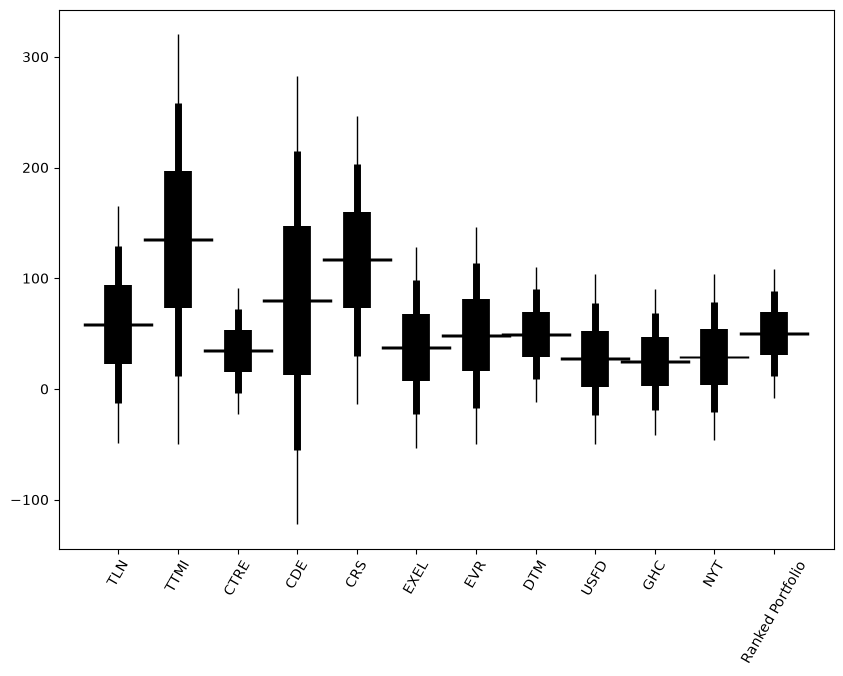

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

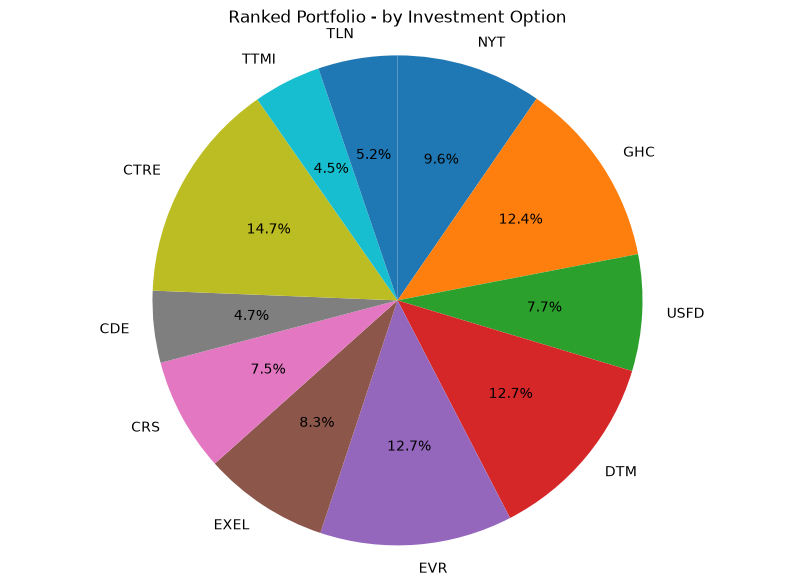

NYT    0.10
GHC    0.12
USFD   0.08
DTM    0.13
EVR    0.13
EXEL   0.08
CRS    0.08
CDE    0.05
CTRE   0.15
TTMI   0.04
TLN    0.05



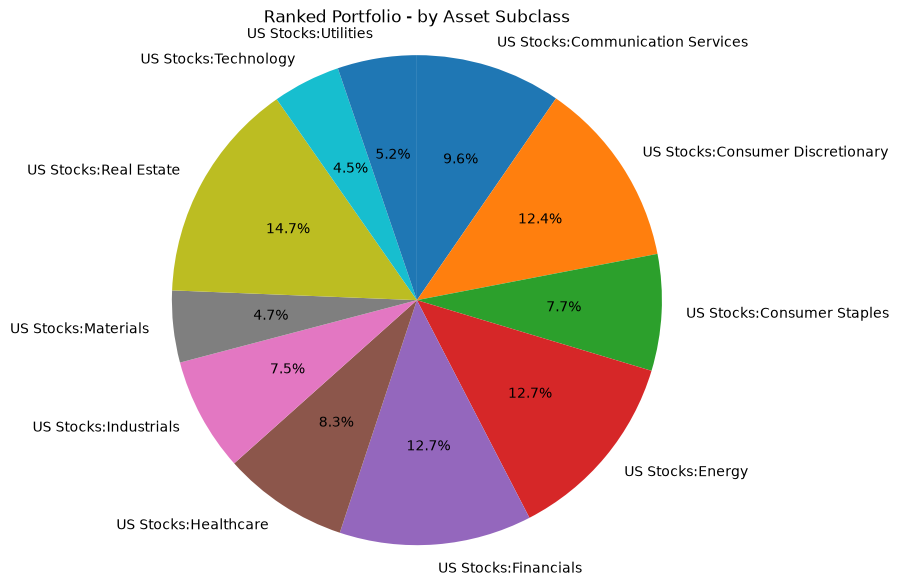

US Stocks:Communication Services   0.10
US Stocks:Consumer Discretionary   0.12
US Stocks:Consumer Staples         0.08
US Stocks:Energy                   0.13
US Stocks:Financials               0.13
US Stocks:Healthcare               0.08
US Stocks:Industrials              0.08
US Stocks:Materials                0.05
US Stocks:Real Estate              0.15
US Stocks:Technology               0.04
US Stocks:Utilities                0.05



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    TLN                            0.0523
    TTMI                           0.0447
    CTRE                           0.1467
    CDE                            0.0474
    CRS                            0.0750
    EXEL                           0.0830
    EVR                            0.1269
    DTM                            0.1275
    USFD                           0.0768
    GHC                            0.1237
    NYT                            0.0961


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).